# Curve curation walkthrough: flood × real estate

**Start here.** This notebook shows how the `flood_real_estate` curves are built: FEMA Hazus depth-damage functions
for the house, warehouse and office, adopted as published, checked against about 100,000 NFIP flood-insurance claims,
with the first-floor height turning water depth above ground into depth inside the building.

The companion [`01_runtime_curve_walkthrough.ipynb`](01_runtime_curve_walkthrough.ipynb) calls the curves the way
Hazard would.

Status: **noncanonical proposal**, current model **v0.2** (bound to the Hazard reference profiles r1; model v0.1 is
kept beside it). The cell documents in `docs/cells/flood_real_estate/` are the source of truth.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "flood_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "flood_real_estate__model_v0_2__docs_r1__curve_artifact.json"
REG = "flood_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/flood/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])
V2 = "flood_real_estate__model_v0_2__docs_r1"  # tag of the model-v0.2 tables

artifact: docs/cells/flood_real_estate/proposed/flood_real_estate__model_v0_2__docs_r1__curve_artifact.json
flood_real_estate | model v0.2 | FLOOD_REAL_ESTATE_HAZUS_NACCS_SCREENING_V0_2 | promotion: proposed | canonical: False


## 1. What the cell is

One pathway (`flood_inundation_contact`) on depth above the first floor (ft). Hazard may send depth above ground
plus a first-floor height instead. A required event-time conditioner, `flood_water_type`, says whether the water is
river/rain flooding or coastal storm surge.

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)
pw = ART["pathways"][0]
display(pd.DataFrame([{"building": NAMES[b], "selector": b, "Hazard profile": prof or "(none: retail kept, unbound)",
                       "reference first-floor height (ft)": pw["reference_first_floor_height_ft"][b]}
                      for b, prof in pw["reference_profile_binding"].items()]))

,field,value
0,cell,flood_real_estate
1,damage code,FLOOD_REAL_ESTATE_HAZUS_NACCS_SCREENING_V0_2
2,model / docs,model v0.2 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_source_native_adopted_tables


,id,treatment,denominator
0,FRE_BUILDING_STRUCTURE,primary_nonzero,"structure replacement cost new of the same reference building (no land, contents, site works or depreciation)"
1,FRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,flood_inundation_contact,flood_depth_above_first_floor_ft,ft,"[-4.0, 24.0]",reference_building_id,flood_water_type,7


,building,selector,Hazard profile,reference first-floor height (ft)
0,House,RE_RES_SFD_1S_SLAB,re_house_1s_wood_slab,0.75
1,Retail (unbound),RE_COM_LOWRISE,"(none: retail kept, unbound)",0.25
2,Warehouse,RE_IND_WAREHOUSE,re_warehouse_1s_steel_slab,0.25
3,Office,RE_COM_OFFICE_3S_SLAB,re_office_3s_slab,0.25


## 2. Evidence register

In [3]:
src = table(f"SOURCE_REGISTER_{REG}.csv")
src["citation"] = src["citation"].str.slice(0, 110)
display(src[["source_id", "citation", "source_role", "evidence_tier", "decision"]])

,source_id,citation,source_role,evidence_tier,decision
0,FRE-S001,"Pollack, A. (2023). Flood Depth-Damage Functions from HAZUS and 2015 North Atlantic Coast Comprehensive Study",curve_data_carrier,T2_public_lab_standard_or_physics,adopt_with_limits
1,FRE-S002,"FEMA. Hazus Flood Model Technical Manual, Hazus 7.0 (June 2025), Table 5-2 Default Damage Functions for Estima",selector_archetype,T2_public_lab_standard_or_physics,adopt
2,FRE-S003,"FEMA Hazus flood depth-damage function library, Hazus 5.1 (as distributed in the CRAN hazus R package, haz_fl_",curve_form,T2_public_lab_standard_or_physics,adopt_with_limits
3,FRE-S004,U.S. Army Corps of Engineers (2015). North Atlantic Coast Comprehensive Study: Resilient Adaptation to Increas,curve_form;selector_archetype,T2_public_lab_standard_or_physics,adopt_with_limits
4,FRE-S005,"U.S. Army Corps of Engineers, Hydrologic Engineering Center. go-consequences, structures/occtypes.json (commit",validation_only,T2_public_lab_standard_or_physics,adopt_with_limits
5,FRE-S006,U.S. Army Corps of Engineers. Economic Guidance Memorandum generic residential depth-damage relationships (one,curve_form;boundary_or_cap,T2_public_lab_standard_or_physics,defer
6,FRE-S007,"U.S. Army Corps of Engineers, Galveston District. Commercial and industrial class depth-damage functions, as c",curve_form,T2_public_lab_standard_or_physics,adopt_with_limits
7,FRE-S008,"Plymouth / Salem coastal flood trial, methodology trial 5 and fit catalogue (Hazard_Modeling branch feature/pl",case_study_severity,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
8,FRE-S009,"U.S. Army Corps of Engineers, Hydrologic Engineering Center. National Structure Inventory technical documentat",selector_archetype,T2_public_lab_standard_or_physics,adopt_with_limits
9,FRE-S010,"FEMA Hazus team. Hazus 6.1 flood damage-function extract, HazusFloodDamageFunctions_Hazus61.xlsx (FEMA-provide",curve_form;selector_archetype,T2_public_lab_standard_or_physics,adopt_with_limits


## 3. The records: published depth-damage tables

Model v0.2 uses one FEMA Hazus function per profile building, for both river and coastal water (decision D-FRE-28):
house DF 129, warehouse DF 341, office DF 431. Retail keeps its v0.1 routing (Hazus DF 217 for fresh water, the
USACE NACCS curve with its min/max building-variant bounds for coastal surge). Values are published points joined by
straight lines; the notebook checks the artifact against the governed ordinates table.

,curve_id,building,water,points,artifact = table
0,FRE_RES_HAZUS_DF129,House,"[freshwater_riverine_or_pluvial, coastal_surge_saline]",29,True
1,FRE_COM_FRESH_HAZUS_DF217,Retail (unbound),freshwater_riverine_or_pluvial,29,True
2,FRE_COM_COAST_NACCS_P2,Retail (unbound),coastal_surge_saline,10,True
3,FRE_COM_COAST_NACCS_P2_MIN,Retail (unbound),coastal_surge_saline,10,True
4,FRE_COM_COAST_NACCS_P2_MAX,Retail (unbound),coastal_surge_saline,10,True
5,FRE_IND_HAZUS_DF341,Warehouse,"[freshwater_riverine_or_pluvial, coastal_surge_saline]",29,True
6,FRE_OFF_HAZUS_DF431,Office,"[freshwater_riverine_or_pluvial, coastal_surge_saline]",29,True


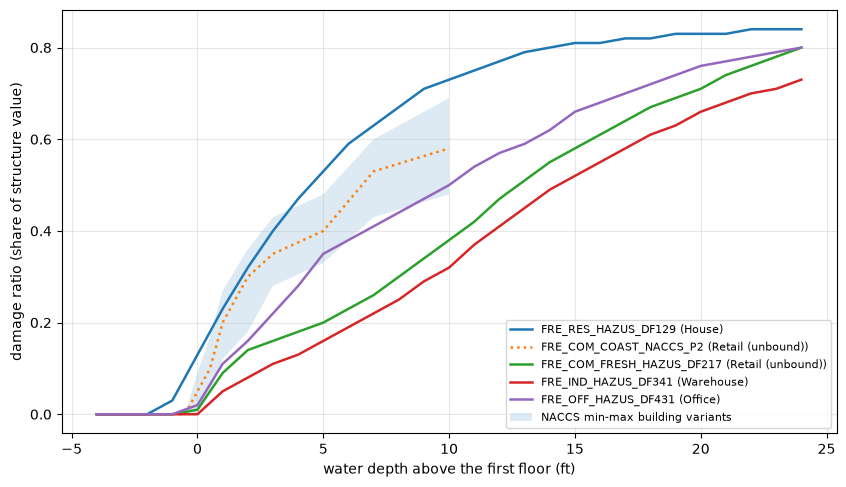

In [4]:
ords = table(f"CURVE_ORDINATES_{V2}.csv")
check = []
for r in ART["pathways"][0]["curve_records"]:
    base_id = r["curve_id"].removesuffix("_MIN").removesuffix("_MAX")  # NACCS bounds share the point curve's rows
    g = ords[(ords.curve_id == base_id) & (ords.band == r["selector_match"]["band"])].sort_values("depth_above_first_floor_ft")
    csv_pts = [[float(x), round(float(y) / 100, 6)] for x, y in zip(g.depth_above_first_floor_ft, g.damage_pct_structure_replacement_cost)]
    art_pts = [[float(x), round(float(y), 6)] for x, y in r["parameters"]["points"]]
    check.append({"curve_id": r["curve_id"], "building": NAMES[r["selector_match"]["reference_building_id"]],
                  "water": r["selector_match"]["flood_water_type"], "points": len(art_pts), "artifact = table": art_pts == csv_pts})
display(pd.DataFrame(check))

fig, ax = plt.subplots(figsize=(10, 5.5))
for cid, g in ords[ords.band == "point"].groupby("curve_id", sort=False):
    g = g.sort_values("depth_above_first_floor_ft")
    b = g.reference_building_id.iloc[0]
    style = ":" if "NACCS" in cid else "-"
    ax.plot(g.depth_above_first_floor_ft, g.damage_pct_structure_replacement_cost / 100, style, lw=1.8, label=f"{cid} ({NAMES[b]})")
env = ords[ords.curve_id == "FRE_COM_COAST_NACCS_P2"].pivot(index="depth_above_first_floor_ft", columns="band",
                                                             values="damage_pct_structure_replacement_cost") / 100
ax.fill_between(env.index, env["lower_bound"], env["upper_bound"], alpha=0.15, label="NACCS min-max building variants")
ax.set_xlabel("water depth above the first floor (ft)")
ax.set_ylabel("damage ratio (share of structure value)")
ax.legend(fontsize=8)
save(fig, "00_depth_damage_records.png")
plt.show()

## 4. Check against NFIP claims

About 100,000 NFIP building claims (OpenFEMA, 2016–2026) were grouped by building type, water type and depth band,
and compared with the curve evaluated on the same claims. A check, not a calibration: claims only exist for buildings
that flooded and were insured.

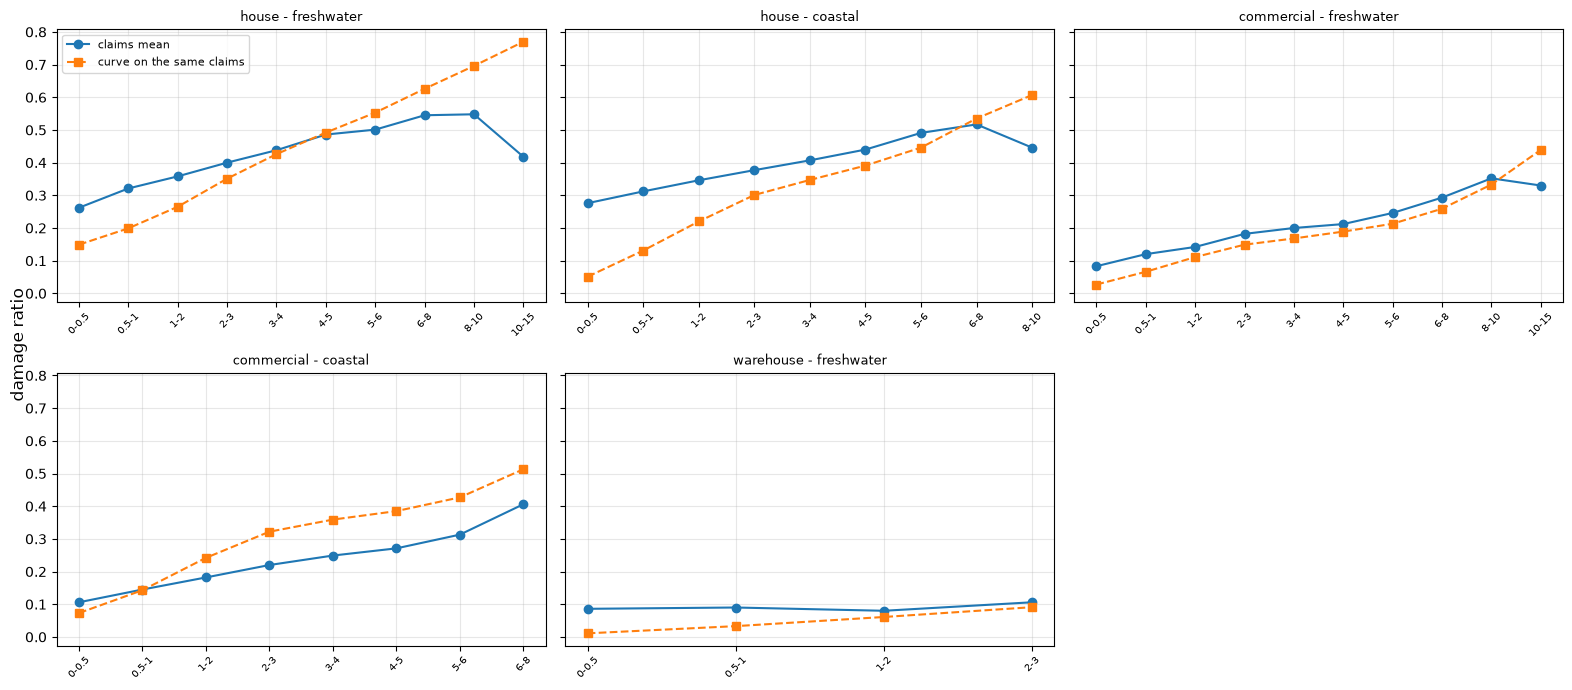

,analogue,water_type,depth_band_ft,n_claims,claims_mean_dr,curve_mean_dr_same_claims,curve_minus_claims_mean
0,house,freshwater_riverine_or_pluvial,0-0.5,15218,0.262,0.149,-0.113
1,house,freshwater_riverine_or_pluvial,0.5-1,9791,0.321,0.199,-0.122
2,house,freshwater_riverine_or_pluvial,1-2,9904,0.358,0.265,-0.093
3,house,freshwater_riverine_or_pluvial,2-3,4334,0.400,0.351,-0.049
4,house,freshwater_riverine_or_pluvial,3-4,2006,0.438,0.426,-0.012
5,house,freshwater_riverine_or_pluvial,4-5,635,0.486,0.492,0.006
6,house,freshwater_riverine_or_pluvial,5-6,263,0.501,0.553,0.052
7,house,freshwater_riverine_or_pluvial,6-8,279,0.545,0.626,0.081
8,house,freshwater_riverine_or_pluvial,8-10,63,0.548,0.696,0.148
9,house,freshwater_riverine_or_pluvial,10-15,34,0.418,0.770,0.352


In [5]:
nfip = table(f"NFIP_CLAIMS_COMPARISON_{REG}.csv")
groups = list(nfip.groupby(["analogue", "water_type"], sort=False))
fig, axes = plt.subplots(2, (len(groups) + 1) // 2, figsize=(16, 7), sharey=True)
for ax, ((analogue, water), g) in zip(axes.flat, groups):
    x = np.arange(len(g))
    ax.plot(x, g.claims_mean_dr, "o-", label="claims mean")
    ax.plot(x, g.curve_mean_dr_same_claims, "s--", label="curve on the same claims")
    ax.set_xticks(x, g.depth_band_ft, rotation=45, fontsize=7)
    ax.set_title(f"{analogue} - {water.split('_')[0]}", fontsize=9)
for ax in list(axes.flat)[len(groups):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=8)
fig.supylabel("damage ratio")
fig.tight_layout()
save(fig, "00_nfip_claims_check.png")
plt.show()
display(nfip[["analogue", "water_type", "depth_band_ft", "n_claims", "claims_mean_dr", "curve_mean_dr_same_claims", "curve_minus_claims_mean"]])

## 5. First-floor height

Hazard's flood depth is above ground. Water only enters at the first floor, so depth inside = depth above ground −
floor height. The profiles give the house 0.75 ft and the slab buildings 0.25 ft; the table shows how much the floor
height moves the damage.

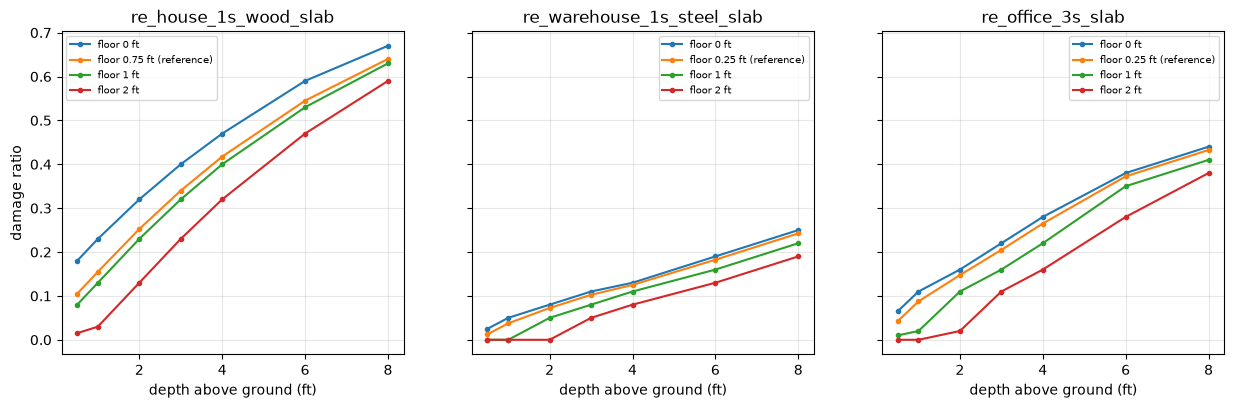

In [6]:
fh = table(f"FLOOR_HEIGHT_SENSITIVITY_{V2}.csv")
fresh = fh[(fh.flood_water_type == "freshwater_riverine_or_pluvial") & (fh.status == "conditional")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (prof, g) in zip(axes, fresh.groupby("profile_id", sort=False)):
    for h, gg in g.groupby("first_floor_height_ft"):
        ref = " (reference)" if gg.is_reference_height.iloc[0] else ""
        ax.plot(gg.depth_above_grade_ft, gg.central_damage_ratio, marker="o", ms=3, label=f"floor {h:g} ft{ref}")
    ax.set_title(prof)
    ax.set_xlabel("depth above ground (ft)")
    ax.legend(fontsize=7)
axes[0].set_ylabel("damage ratio")
save(fig, "00_floor_height_sensitivity.png")
plt.show()

## 6. Decisions

The decision log is shared by v0.1 and v0.2; D-FRE-26 to D-FRE-28 are the v0.2 changes.

In [7]:
log = decision_log(PROP / f"DECISION_LOG_{REG}.md")
display(log.groupby("status").size().rename("decisions").to_frame())
display(log)

,decisions
status,
JL decided,2
proposed,26


,id,status,decision
0,D-FRE-01,proposed,"One cell, `flood_real_estate`, for all three asset types. The reference building is a selector on one failure unit."
1,D-FRE-02,proposed,"Model the structure only, as a fraction of replacement cost new. Land, contents, depreciation and market value are excluded."
2,D-FRE-03,proposed,One whole-building curve per reference building for flood v0.1/v1.
3,D-FRE-04,proposed,"One still-water pathway, `flood_inundation_contact`, for riverine, pluvial and coastal water."
4,D-FRE-05,proposed,Water type is an event-time conditioner: freshwater → Hazus default (Table 5-2); coastal surge → NACCS 2015; unknown → withhold.
5,D-FRE-06,proposed,"Declare `flood_wave_velocity` (wave impact, fast-moving water, scour) as a separate pathway, deferred: no curve in v0.1, and wave damage is withheld, not zero."
6,D-FRE-07,proposed,"Axis = depth above first finished floor, in ft; outside the published range withholds."
7,D-FRE-08,proposed,"Choose candidate curves by the Hazus default per occupancy (Table 5-2), not by picking among class-specific curves."
8,D-FRE-09,proposed,"Building subsystem and component names (`BUILDING`, `BUILDING_STRUCTURE_ASSEMBLY`, `CONTENTS`) are proposals. *Owner: platform / reviewer.*"
9,D-FRE-10,proposed,"Platform type labels (Hotel → Commercial, Warehouse → Industrial) do not affect the curve; the curve keys on the recorded Hazus occupancy. *Owner: reviewer ..."


## 7. Parameter tiers

In [8]:
tiers = pd.DataFrame(ART["parameter_tier_table"])
cols = [c for c in ("parameter", "curve_id", "value", "tier", "status") if c in tiers.columns]
display(tiers[cols])
display(tiers.groupby("tier").size().rename("parameters").to_frame())

,parameter,curve_id,value,tier,status
0,axis_definition,all,"flood depth above first finished floor, ft",T2_public_lab_standard_or_physics,proposed
1,curve_form,all,straight lines between published points (piecewise linear),T2_public_lab_standard_or_physics,proposed
2,axis_bridge,all,depth_above_floor = depth_above_grade − first_floor_height (same datum required),T2_public_lab_standard_or_physics,proposed
3,RE_RES_SFD_1S_SLAB.freshwater.ordinates,FRE_RES_FRESH_HAZUS_DF129,"Hazus DF 129, −4 to 24 ft (USACE-IWR)",T2_public_lab_standard_or_physics,proposed
4,RE_COM_LOWRISE.freshwater.ordinates,FRE_COM_FRESH_HAZUS_DF217,"Hazus DF 217, −4 to 24 ft (USACE Galveston, average of 47 retail classes)",T2_public_lab_standard_or_physics,proposed
5,RE_IND_WAREHOUSE.freshwater.ordinates,FRE_IND_FRESH_HAZUS_DF341,"Hazus DF 341, −4 to 24 ft (USACE Galveston, average of 22 wholesale/warehouse classes)",T2_public_lab_standard_or_physics,proposed
6,RE_RES_SFD_1S_SLAB.coastal.ordinates,FRE_RES_COAST_NACCS_5A,"NACCS RES1-1SNB Min/ML/Max at −1, −0.5, 0, 0.5, 1, 2, 3, 5, 7, 10 ft",T2_public_lab_standard_or_physics,proposed
7,RE_COM_LOWRISE.coastal.ordinates,FRE_COM_COAST_NACCS_P2,NACCS COM-ENG Min/ML/Max at the ten published depths,T2_public_lab_standard_or_physics,proposed
8,RE_IND_WAREHOUSE.coastal.ordinates,FRE_IND_COAST_NACCS_P3,NACCS COM-PRE Min/ML/Max at the ten published depths,T2_public_lab_standard_or_physics,proposed
9,naccs_runtime_band,FRE_*_COAST_NACCS_*,"ML is the point curve; Min and Max are building-variant bounds, not a probability spread",T2_public_lab_standard_or_physics,proposed


,parameters
tier,
T2_public_lab_standard_or_physics,15
T3_engineering_proxy_or_adjacent_empirical,3
T4_placeholder_or_expert_judgment,2


## 8. What is still open

- Coastal use of the river-calibrated FEMA curves for the house, warehouse and office (coastal claims for commercial
  buildings run higher); waves and fast-moving water are not modelled.
- The office curve (DF 431) reads about 1.6× the claims for 3+ storey buildings; kept as published.
- Hazard-side: the dry-ground rule when floor-relative depth is sent, floor heights, the coastal depth basis, and
  value coverage.

In [9]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,flood_inundation_contact,conditional,withheld,nonprobabilistic_epistemic_envelope,FRE_BUILDING_CONTENTS


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - the reviewer accepts scope D-FRE-01 to D-FRE-06 and selections D-FRE-16 to D-FRE-28
  - consumer value qualification of each reference budget against the structure denominator
  - consumer integration resolves record-level ranges, routing and the dry-ground rule
  - independent review of the package
